# The model zoo, measured -- and one normalizer that was measured wrong

Every checkpoint in the zoo that the integrated runtime can load was scored on
one shared evaluation, three generation seeds each. Two of them were scored
under a normalizer they were never trained with; this notebook shows what that
cost, and what it does not explain.

All figures read `docs/evidence/zoo_benchmark.json`, assembled from the summaries the benchmark
itself wrote. No distance is recomputed here.

In [1]:
import io, json, pathlib, statistics as st
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

EV = pathlib.Path("docs/evidence/zoo_benchmark.json")
if not EV.exists():
    EV = pathlib.Path("..") / ".." / "docs/evidence/zoo_benchmark.json"
E = json.loads(EV.read_text())

META, REG, PINS = E["evaluation"], E["registry"], E["pins_legacy_norm"]
FIXED, LEGACY, HIST = E["fixed_eps"], E["legacy_eps"], E["historical_78m"]
FLOOR = E.get("divergence_floor", {}).get("intervals", {})
NULLF = E.get("per_window_null_floor", {})
INK, WARN, GREY, GOOD = "#1f4e79", "#c05a00", "#93a5b5", "#3d7a5a"

plt.rcParams.update({"figure.dpi": 300, "savefig.dpi": 300, "axes.grid": True, "grid.alpha": .25,
                     "axes.spines.top": False, "axes.spines.right": False})
plt.ioff()

def show(fig):
    """Render as a 256-colour palette PNG so the committed notebook stays small
    enough for GitHub to render it inline."""
    buf = io.BytesIO()
    fig.savefig(buf, format="png", bbox_inches="tight")
    plt.close(fig); buf.seek(0)
    try:
        from PIL import Image as _PIL
        im = _PIL.open(buf).convert("RGB").quantize(colors=256)
        out = io.BytesIO(); im.save(out, format="PNG", optimize=True)
        display(Image(data=out.getvalue()))
    except ImportError:
        display(Image(data=buf.getvalue()))

def ws(d, model):
    """The model's WS-21 under each generation seed."""
    return [v["ws21"] for _, v in sorted(d.get(model, {}).items())]

SCORED = sorted(FIXED, key=lambda m: st.mean(ws(FIXED, m)))
print(f"{len(SCORED)} models x {len(META['seeds'])} seeds on "
      f"{META['stock']} {META['period']}, {META['sequences']} sequences")
print(f"legacy-epsilon re-runs: {', '.join(sorted(LEGACY))}")

19 models x 3 seeds on GOOG 2026-01, 3136 sequences
legacy-epsilon re-runs: m3-goog-6m-zerobook, m3-megacap8-78m-wce, m3-sp500-78m-s42


## Figure 1 - the leaderboard

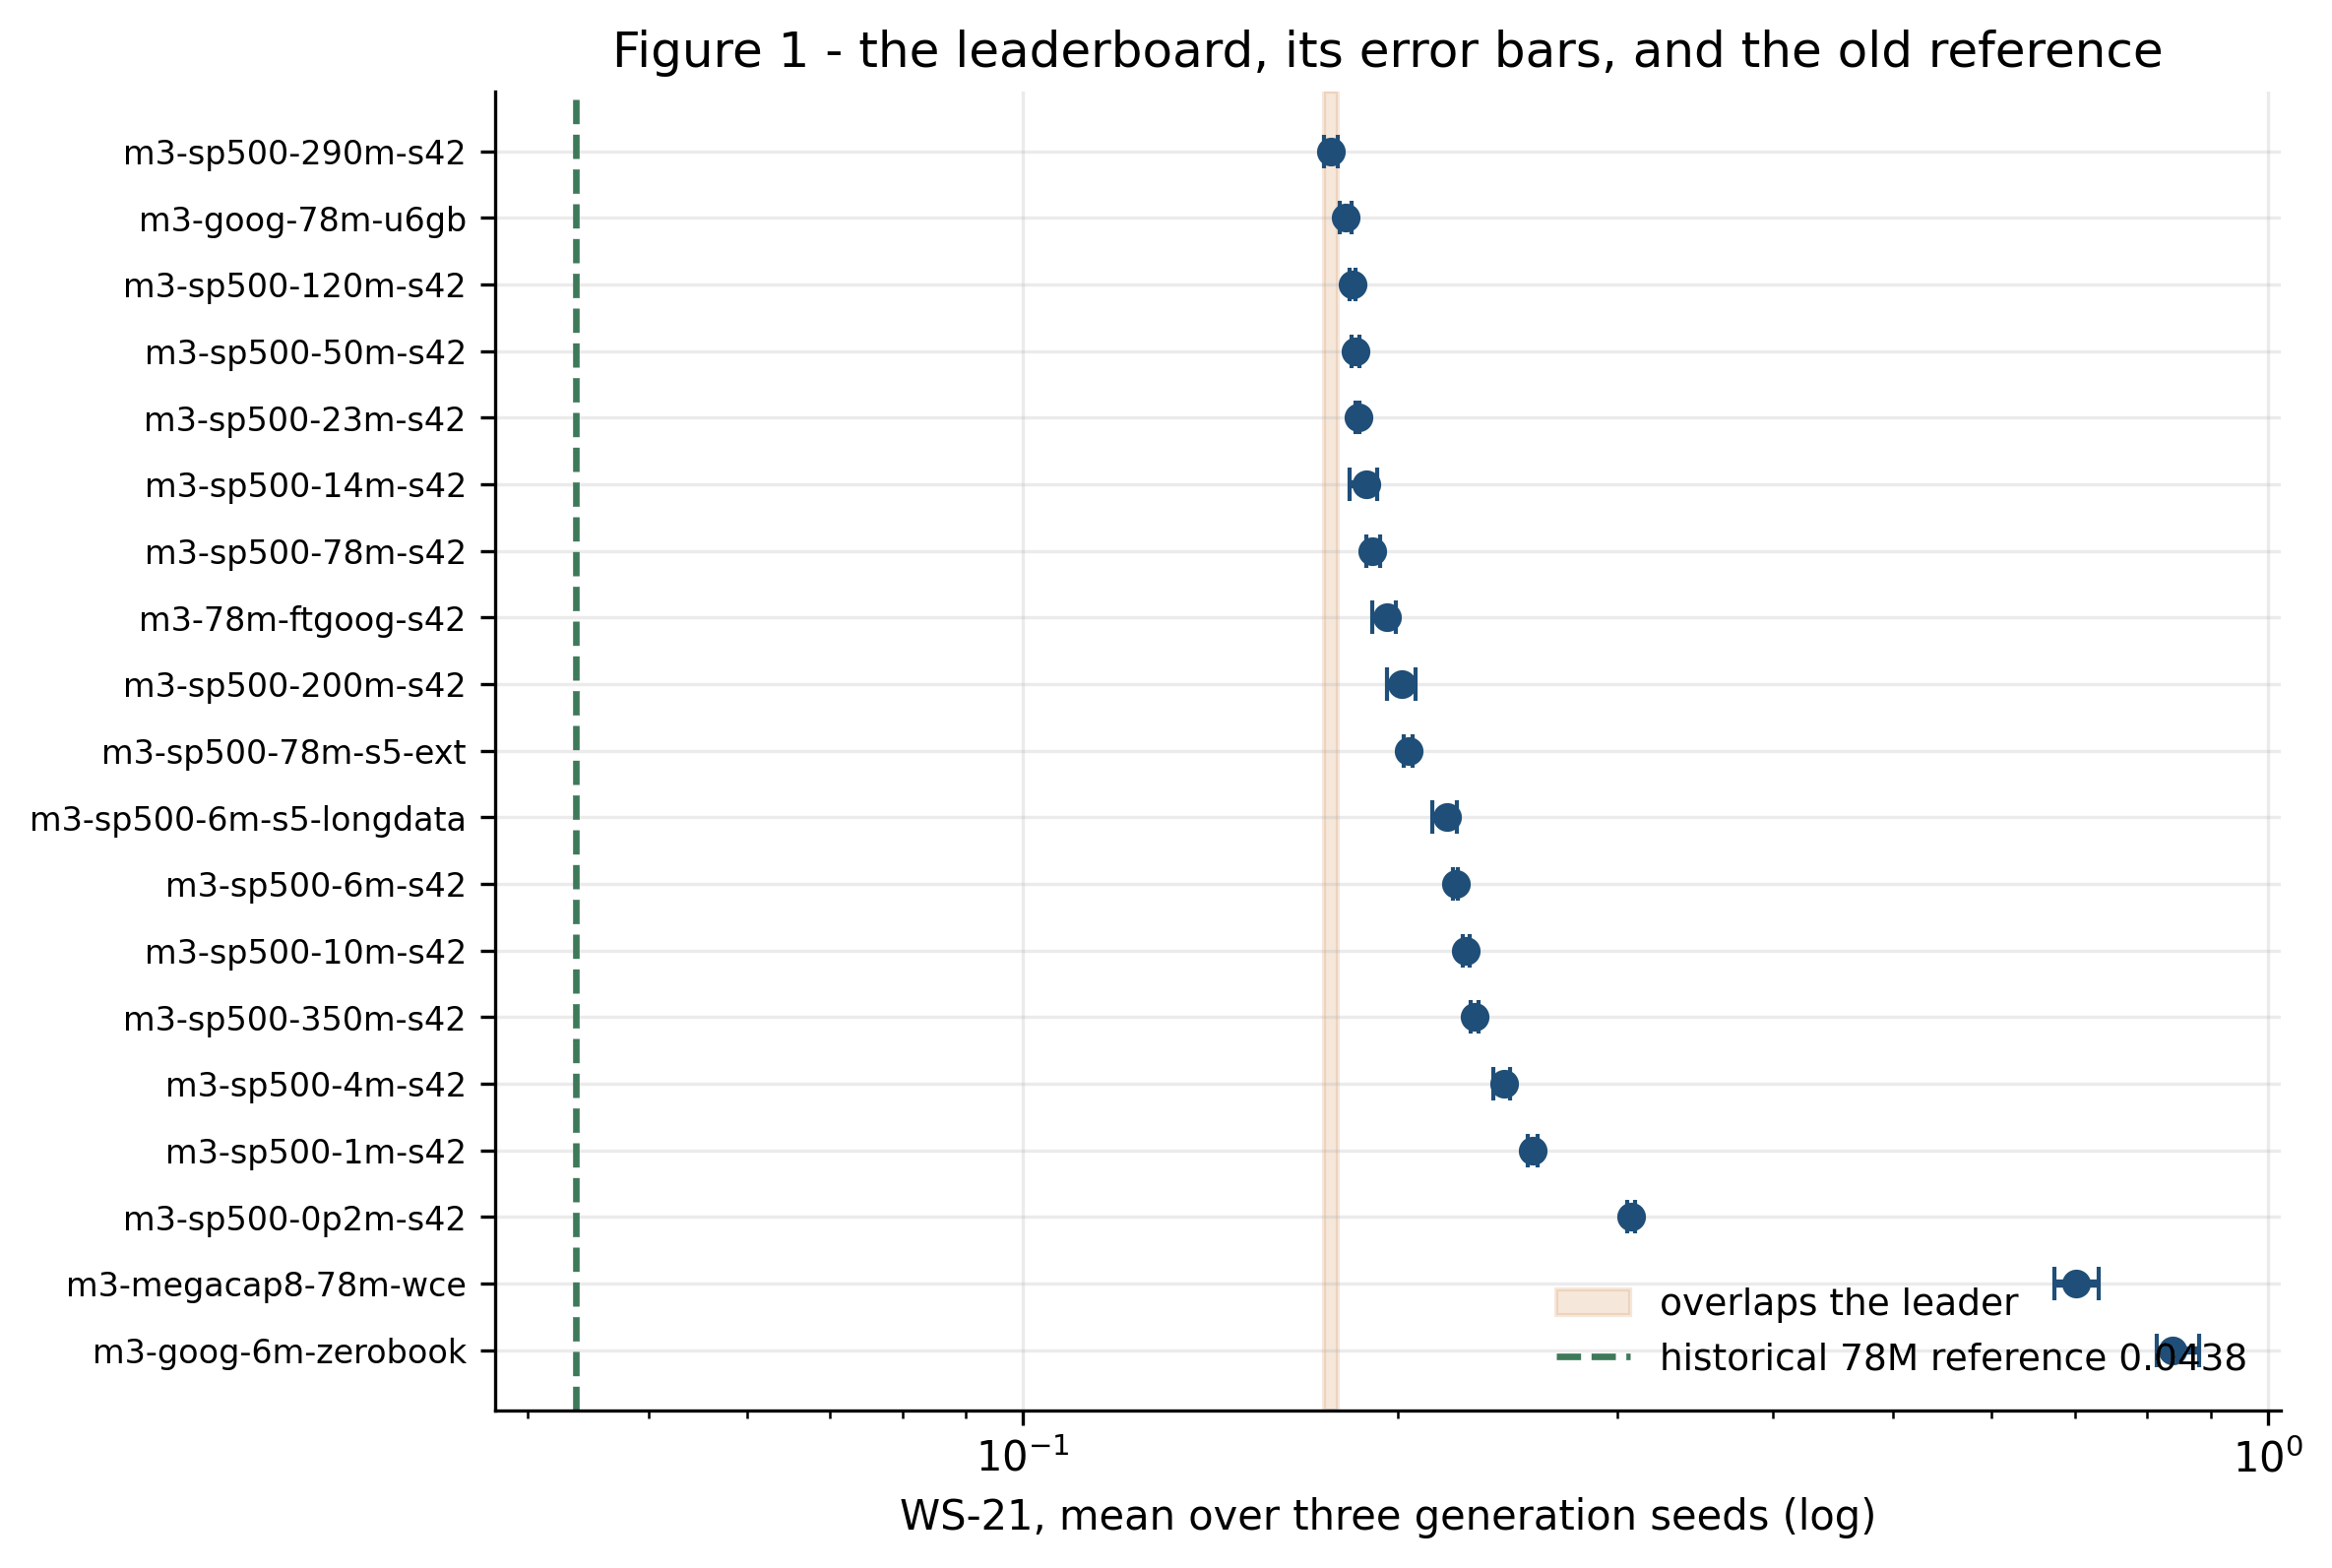

In [2]:
means = [st.mean(ws(FIXED, m)) for m in SCORED]
lo = [min(ws(FIXED, m)) for m in SCORED]; hi = [max(ws(FIXED, m)) for m in SCORED]
y = np.arange(len(SCORED))
fig, ax = plt.subplots(figsize=(7.8, 5.8))
ax.errorbar(means, y, xerr=[np.array(means) - lo, np.array(hi) - np.array(means)],
            fmt="o", color=INK, ecolor=INK, elinewidth=2, capsize=4)
ax.axvspan(min(lo), hi[0], color=WARN, alpha=.14, label="overlaps the leader")
ax.axvline(HIST["ws21"], ls="--", lw=1.6, color=GOOD,
           label=f"historical 78M reference {HIST['ws21']:.4f}")
ax.set_xscale("log"); ax.set_yticks(y); ax.set_yticklabels(SCORED, fontsize=8)
ax.invert_yaxis(); ax.set_xlabel("WS-21, mean over three generation seeds (log)")
ax.set_title("Figure 1 - the leaderboard, its error bars, and the old reference")
ax.legend(frameon=False, loc="lower right", fontsize=9)
show(fig)

*The leader is separated from the field, the amber band is the group its error bar cannot be told apart from, and the green line is where a 78M Mamba3 sat before the epsilon fix.*

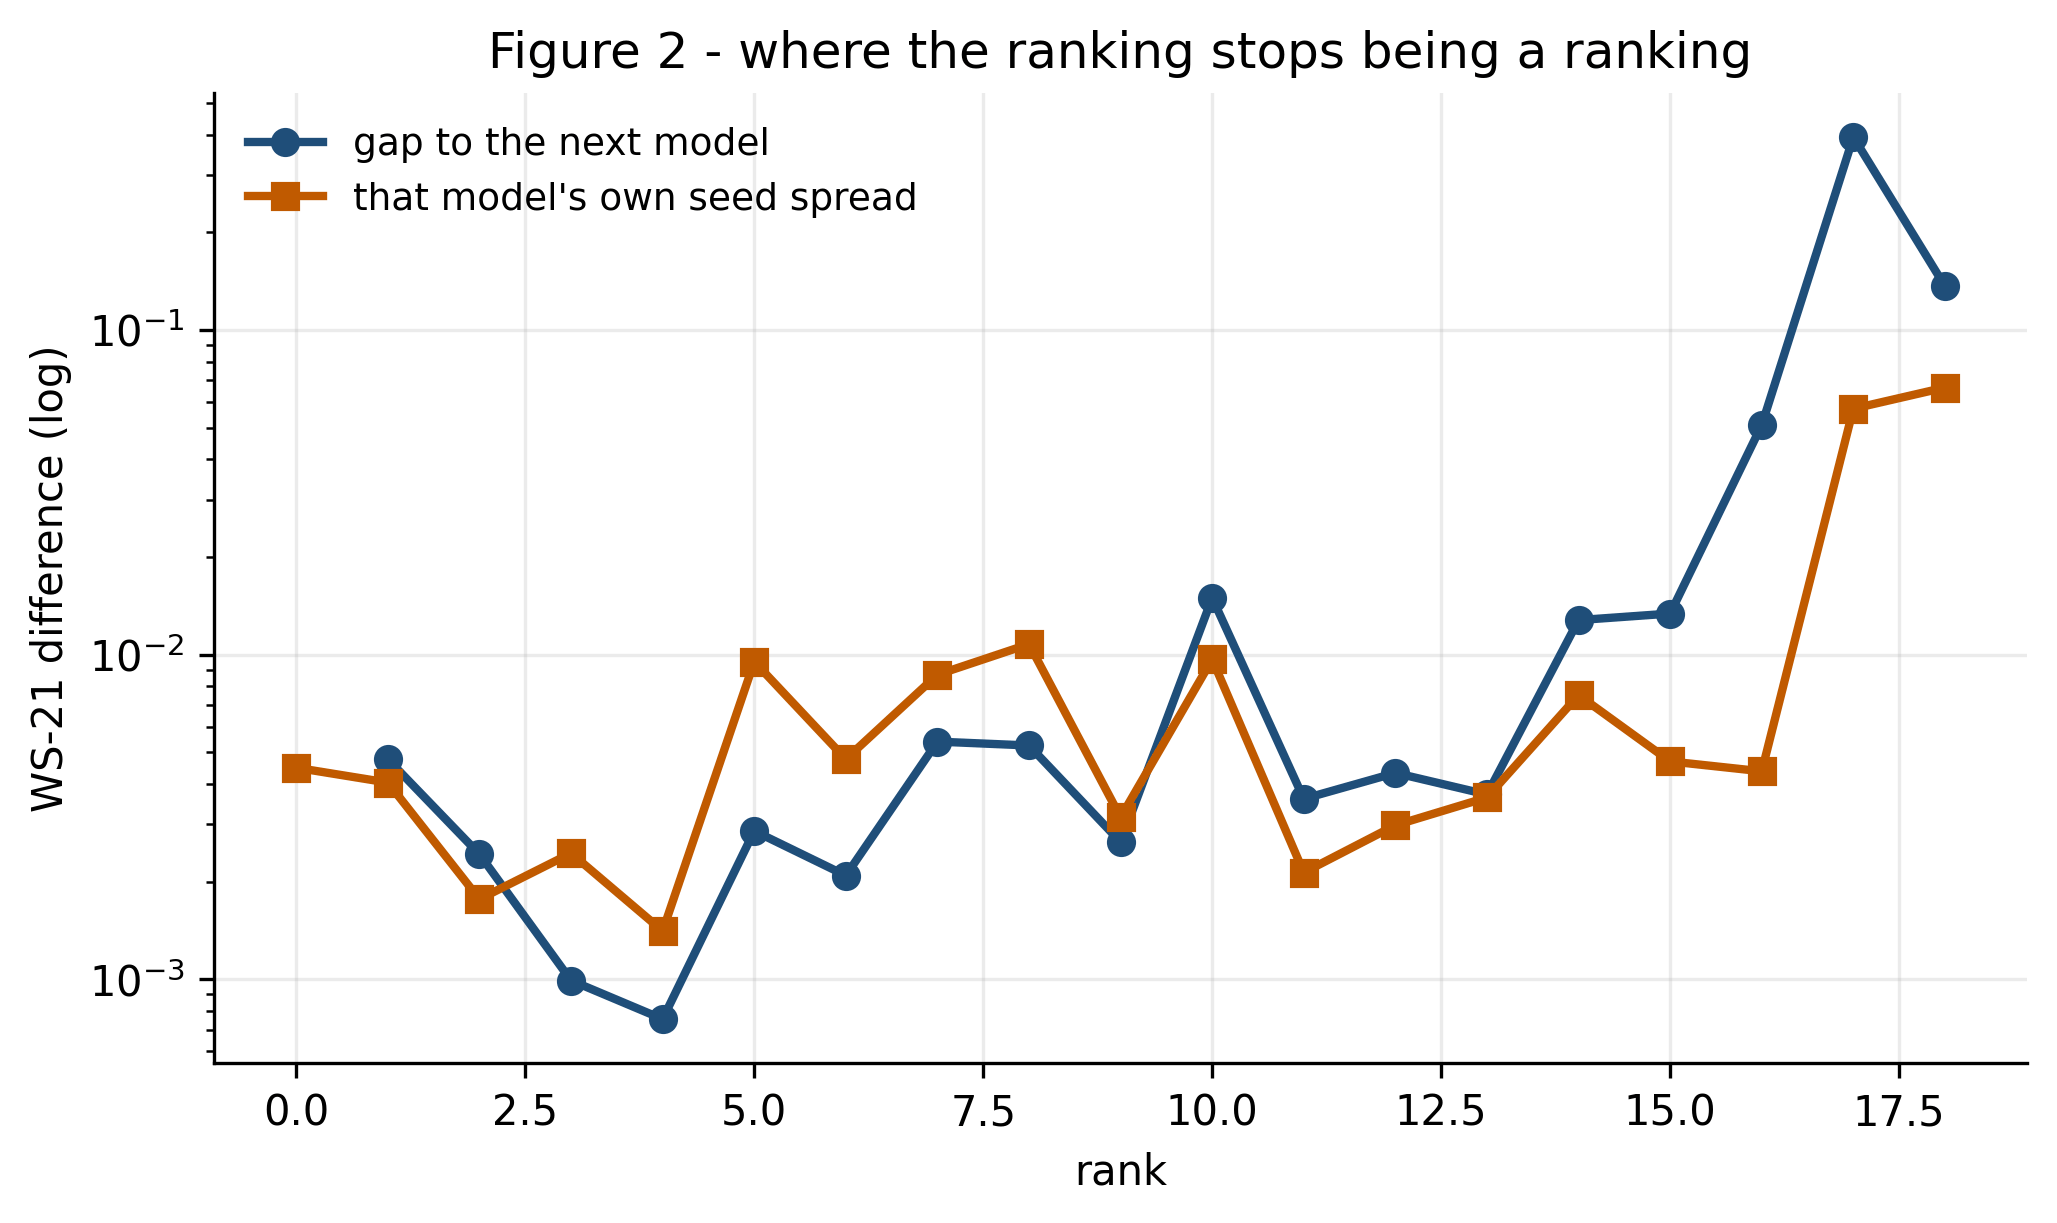

In [3]:
tied = [m for m in SCORED[1:] if min(ws(FIXED, m)) <= max(ws(FIXED, SCORED[1]))]
gaps = [st.mean(ws(FIXED, b)) - st.mean(ws(FIXED, a))
        for a, b in zip(SCORED, SCORED[1:])]
spreads = [max(ws(FIXED, m)) - min(ws(FIXED, m)) for m in SCORED]
fig, ax = plt.subplots(figsize=(7.8, 4.2))
ax.plot(np.arange(1, len(gaps) + 1), gaps, marker="o", lw=2, color=INK,
        label="gap to the next model")
ax.plot(np.arange(len(spreads)), spreads, marker="s", lw=2, color=WARN,
        label="that model's own seed spread")
ax.set_yscale("log"); ax.set_xlabel("rank"); ax.set_ylabel("WS-21 difference (log)")
ax.set_title("Figure 2 - where the ranking stops being a ranking")
ax.legend(frameon=False, fontsize=9)
show(fig)

*Below rank two the gap between neighbours falls under their own seed spread: past that point the table is a list, not a ranking.*

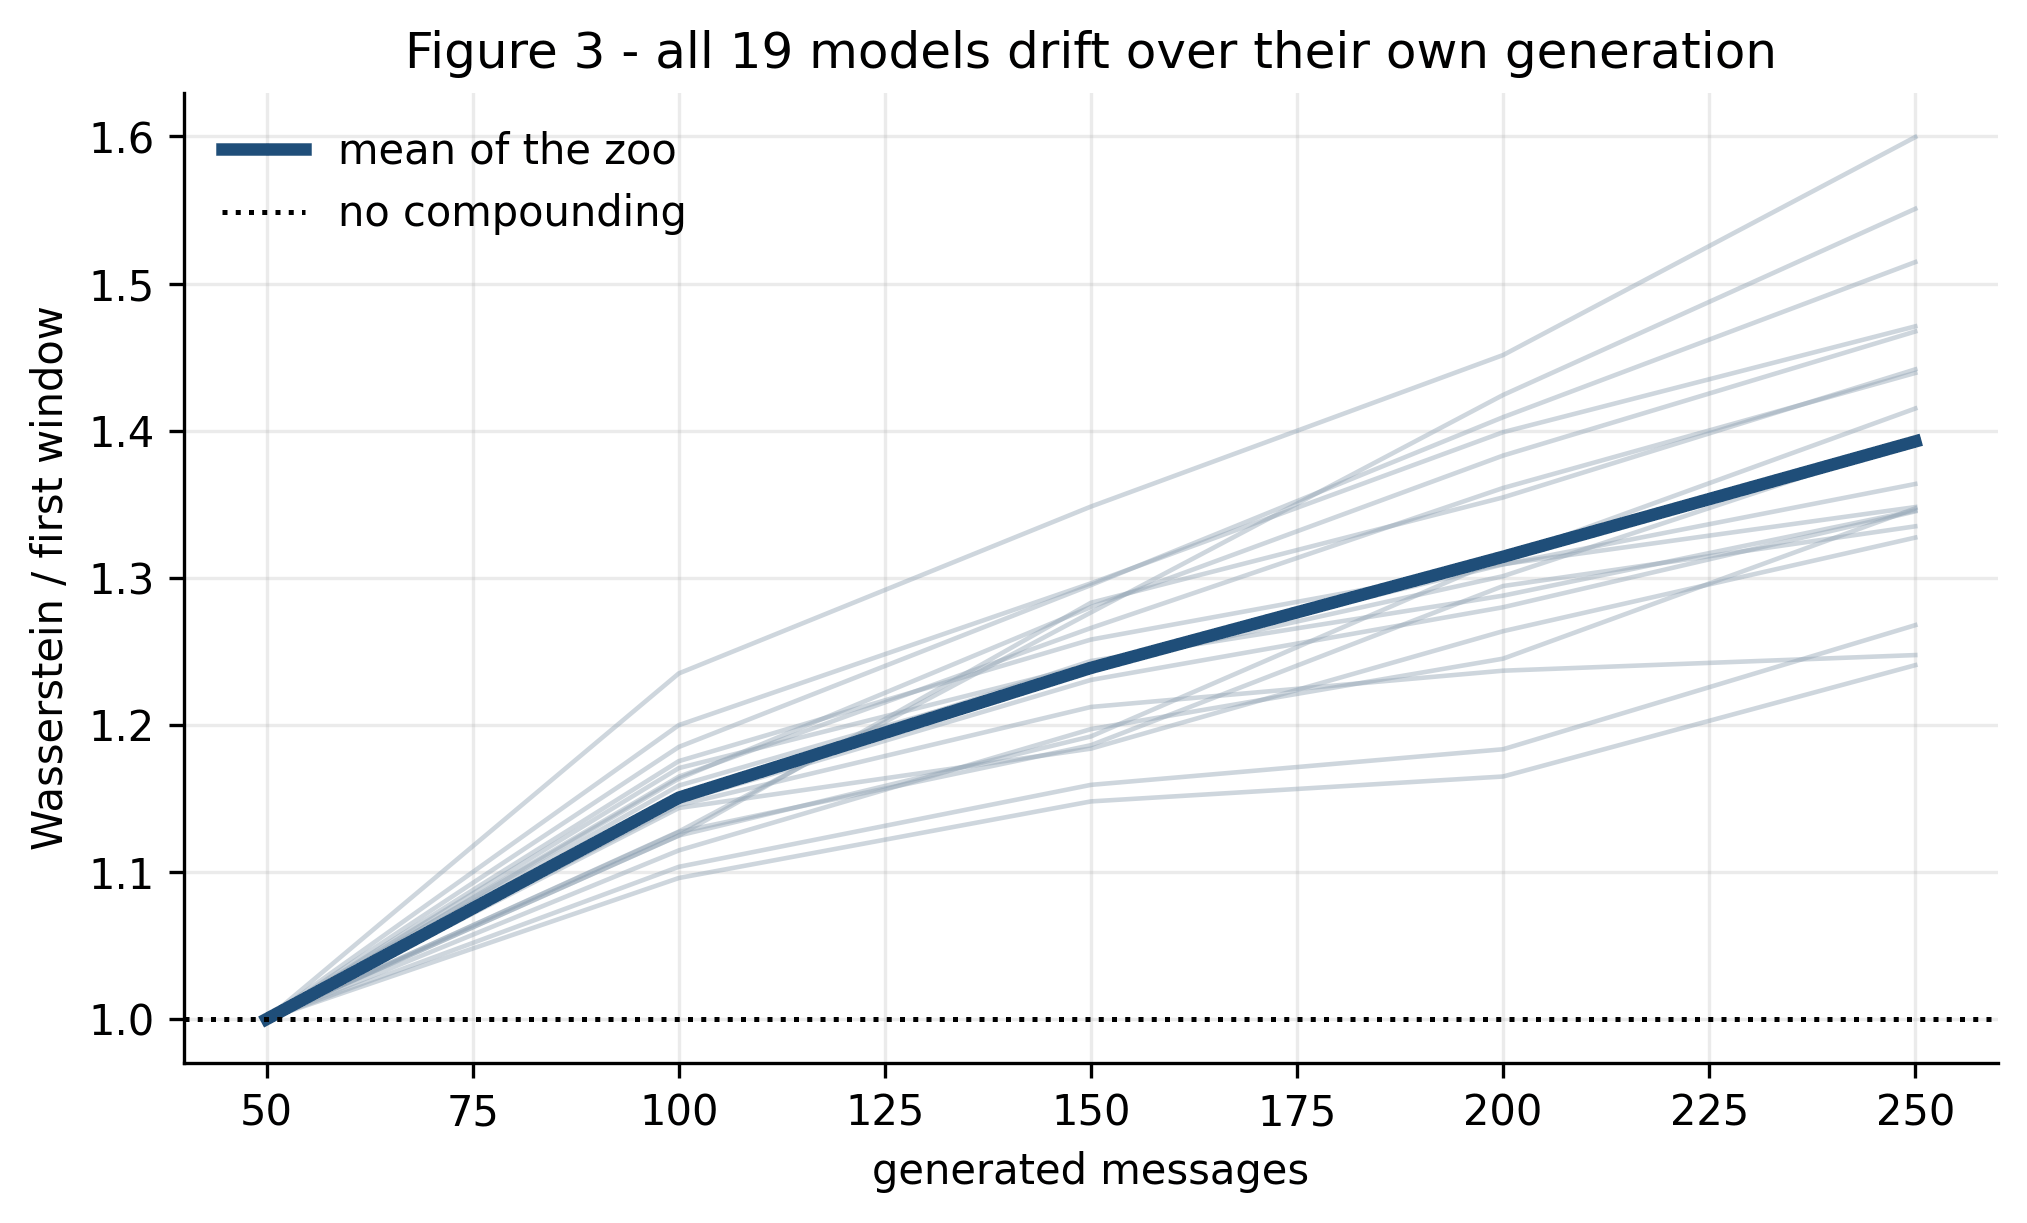

In [4]:
curves = [(m, FIXED[m]["2026"]) for m in SCORED if FIXED[m]["2026"].get("div_curve")]
axis = curves[0][1]["div_axis"]
rel = np.array([[c / v["div_curve"][0] for c in v["div_curve"]] for _, v in curves])
fig, ax = plt.subplots(figsize=(7.8, 4.2))
for r in rel:
    ax.plot(axis, r, lw=1.1, alpha=.45, color=GREY)
ax.plot(axis, rel.mean(axis=0), lw=3, color=INK, label="mean of the zoo")
ax.axhline(1.0, ls=":", color="k", lw=1.2, label="no compounding")
ax.set_xlabel("generated messages"); ax.set_ylabel("Wasserstein / first window")
ax.set_title(f"Figure 3 - all {len(curves)} models drift over their own generation")
ax.legend(frameon=False); show(fig)

*No model is exempt from drift; the panel mean is 40% worse by the last window than the first, which the pooled score above averages away.*

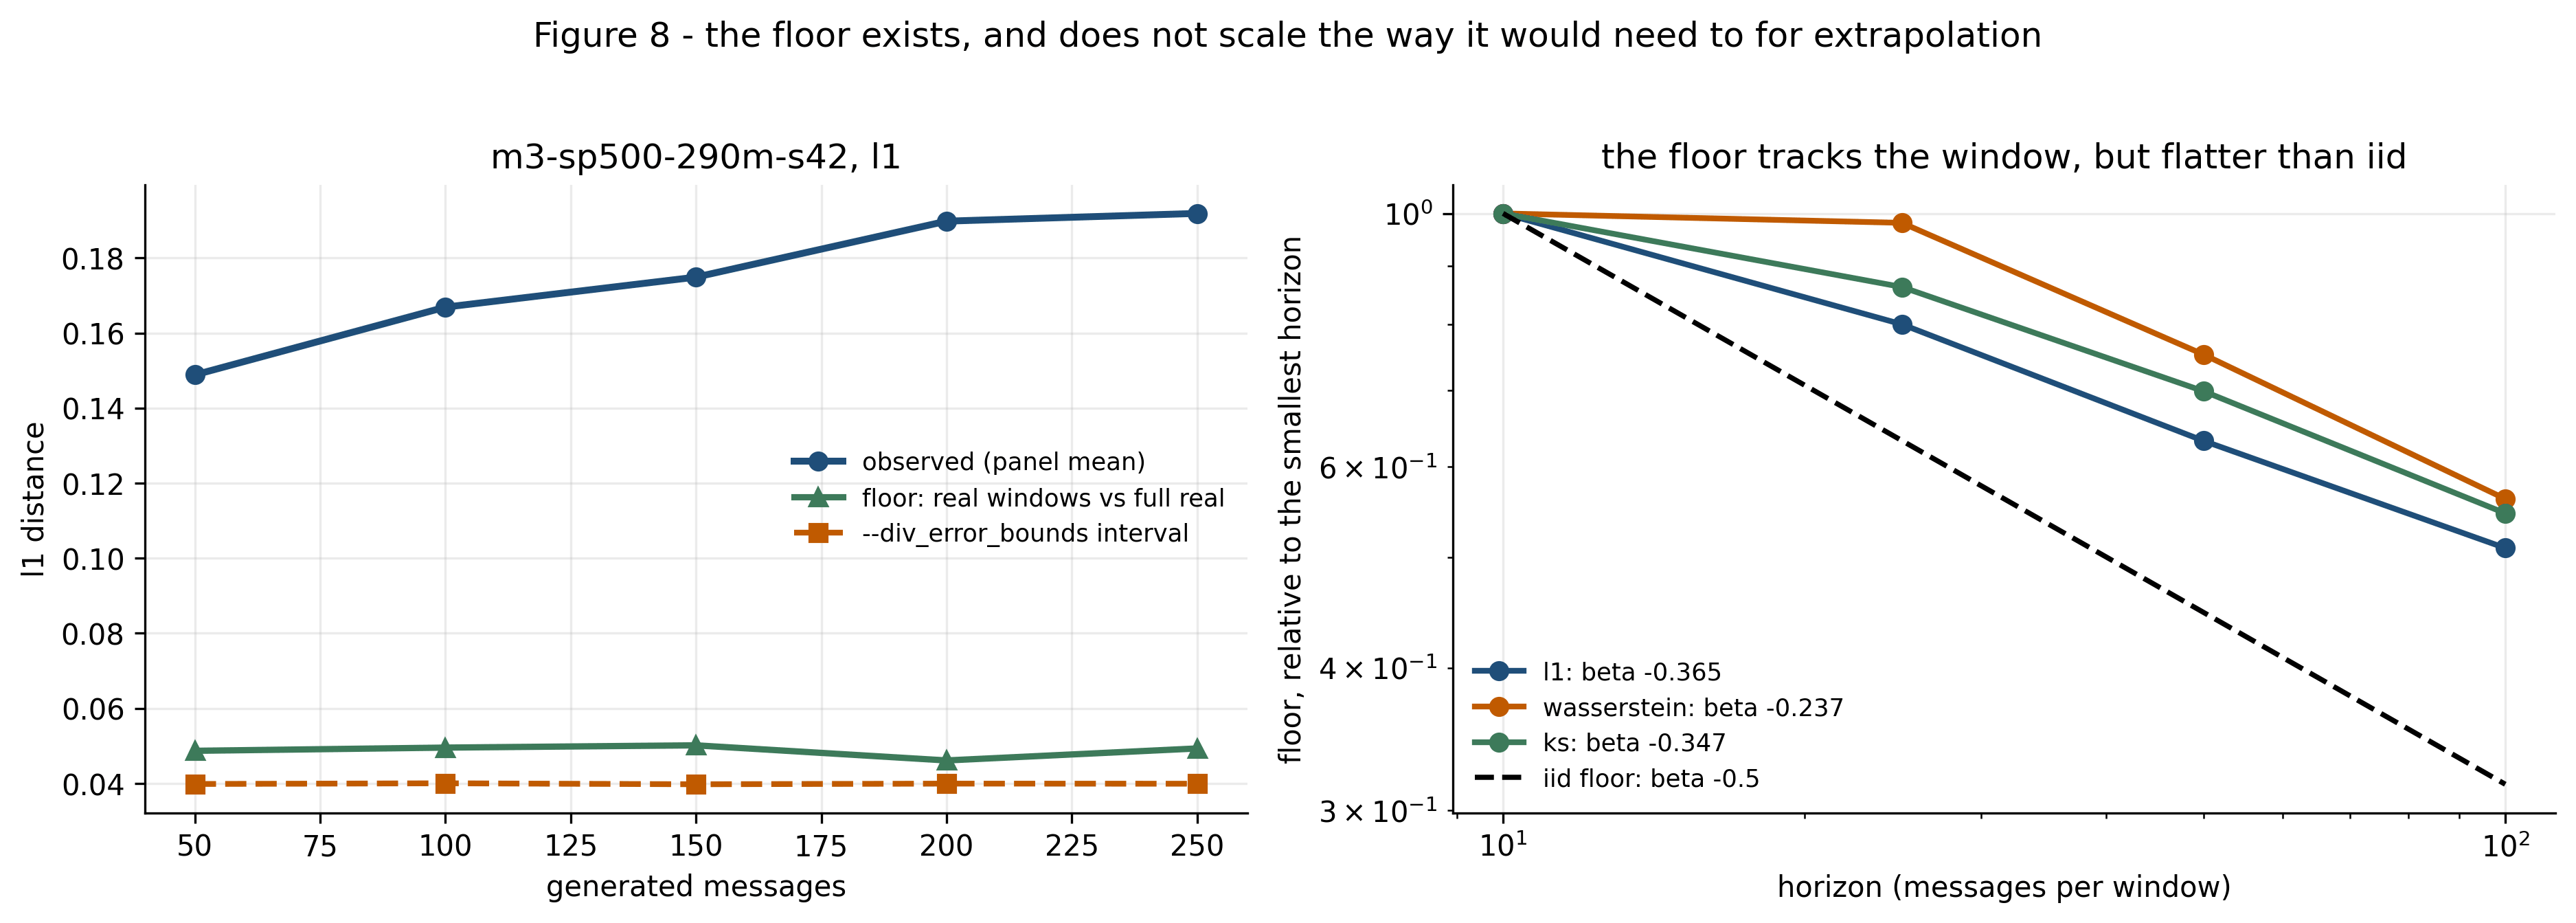

In [5]:
# Left: the observed curve and the two candidate references. Right: how each
# reference responds to the window size, which is what tells them apart -- at
# any single horizon they sit close together and the left panel cannot.
FD = "l1"
mdl = SCORED[0]
axis = FIXED[mdl]["2026"]["div_axis"]
cv = FIXED[mdl]["2026"]["div_curves_by_distance"][FD]
base = {f: [(w[0] + w[1]) / 2 for w in per[FD]] for f, per in FLOOR.items()
        if per.get(FD) and all(w is not None for w in per[FD])}
b50 = [float(np.mean([v[i] for v in base.values()])) for i in range(len(axis))]
nf = NULLF.get("curves", {})
n50 = {f: c[FD] for f, c in nf.get("50", {}).items() if c.get(FD)}
nfl = [float(np.mean([v[i] for v in n50.values()])) for i in range(len(axis))]

fig, (ax, bx) = plt.subplots(1, 2, figsize=(12.6, 4.3))
ax.plot(axis, cv, marker="o", lw=2.4, color=INK, label="observed (panel mean)")
ax.plot(axis, nfl, marker="^", lw=2.2, color=GOOD, label="floor: real windows vs full real")
ax.plot(axis, b50, marker="s", lw=2.0, ls="--", color=WARN, label="--div_error_bounds interval")
ax.set_xlabel("generated messages"); ax.set_ylabel(f"{FD} distance")
ax.set_title(f"{mdl}, {FD}"); ax.legend(frameon=False, fontsize=8.5)

# The floor measured at four horizons, per distance, against the iid slope.
HZS = NULLF.get("scaling_fit", {}).get("horizons", [])
fitd = NULLF.get("scaling_fit", {}).get("by_distance", {})
for dist, col in (("l1", INK), ("wasserstein", WARN), ("ks", GOOD)):
    pts = []
    for h in HZS:
        cur = {f: c[dist] for f, c in nf.get(str(h), {}).items() if c.get(dist)}
        if cur:
            pts.append((h, float(np.mean([np.mean(v) for v in cur.values()]))))
    if len(pts) < 2:
        continue
    xs = [p[0] for p in pts]; ys = [p[1] / pts[0][1] for p in pts]
    b = fitd.get(dist, {}).get("beta_median", float("nan"))
    bx.plot(xs, ys, marker="o", lw=2, color=col, label=f"{dist}: beta {b:+.3f}")
if HZS:
    ref = [(h / HZS[0]) ** -0.5 for h in HZS]
    bx.plot(HZS, ref, ls="--", lw=1.8, color="k", label="iid floor: beta -0.5")
bx.set_xscale("log"); bx.set_yscale("log")
bx.set_xlabel("horizon (messages per window)")
bx.set_ylabel("floor, relative to the smallest horizon")
bx.set_title("the floor tracks the window, but flatter than iid")
bx.legend(frameon=False, fontsize=8.5)
fig.suptitle("Figure 8 - the floor exists, and does not scale the way it would need to "
             "for extrapolation", y=1.03)
fig.tight_layout(); show(fig)

*Left: at one horizon the two references are close and the picture cannot
separate them. Right: only their response to the window size can. The floor
built from real windows tracks the window; `--div_error_bounds` does not,
because it compares two copies of the whole real sample and never sees the
window.*

So there is a floor, and it is the real-windows one. But it does not fall as
`n^-1/2`: fitted across horizons 10, 25, 50 and 100 the exponent is -0.365 for
L1, -0.347 for KS and **-0.237 for Wasserstein**, with R^2 around 0.97-0.99 --
systematic, not noise. Dropping horizon 10, whose window is shorter than the
~16-message run length, moves L1 to -0.390 and leaves Wasserstein at -0.223, so
correlation at that scale is not the main cause.

The consequence is narrow and worth stating exactly. The floor may be read at
the horizon it was measured at; it may **not** be extrapolated to another
window size by assuming iid scaling. That bites hardest on Wasserstein, which
is the distance WS-21 reports.

An earlier version of this notebook compared two horizons, found L1 at 1.332
against sqrt(2) = 1.414, and called it a match. Four horizons show that was an
artefact of using two.

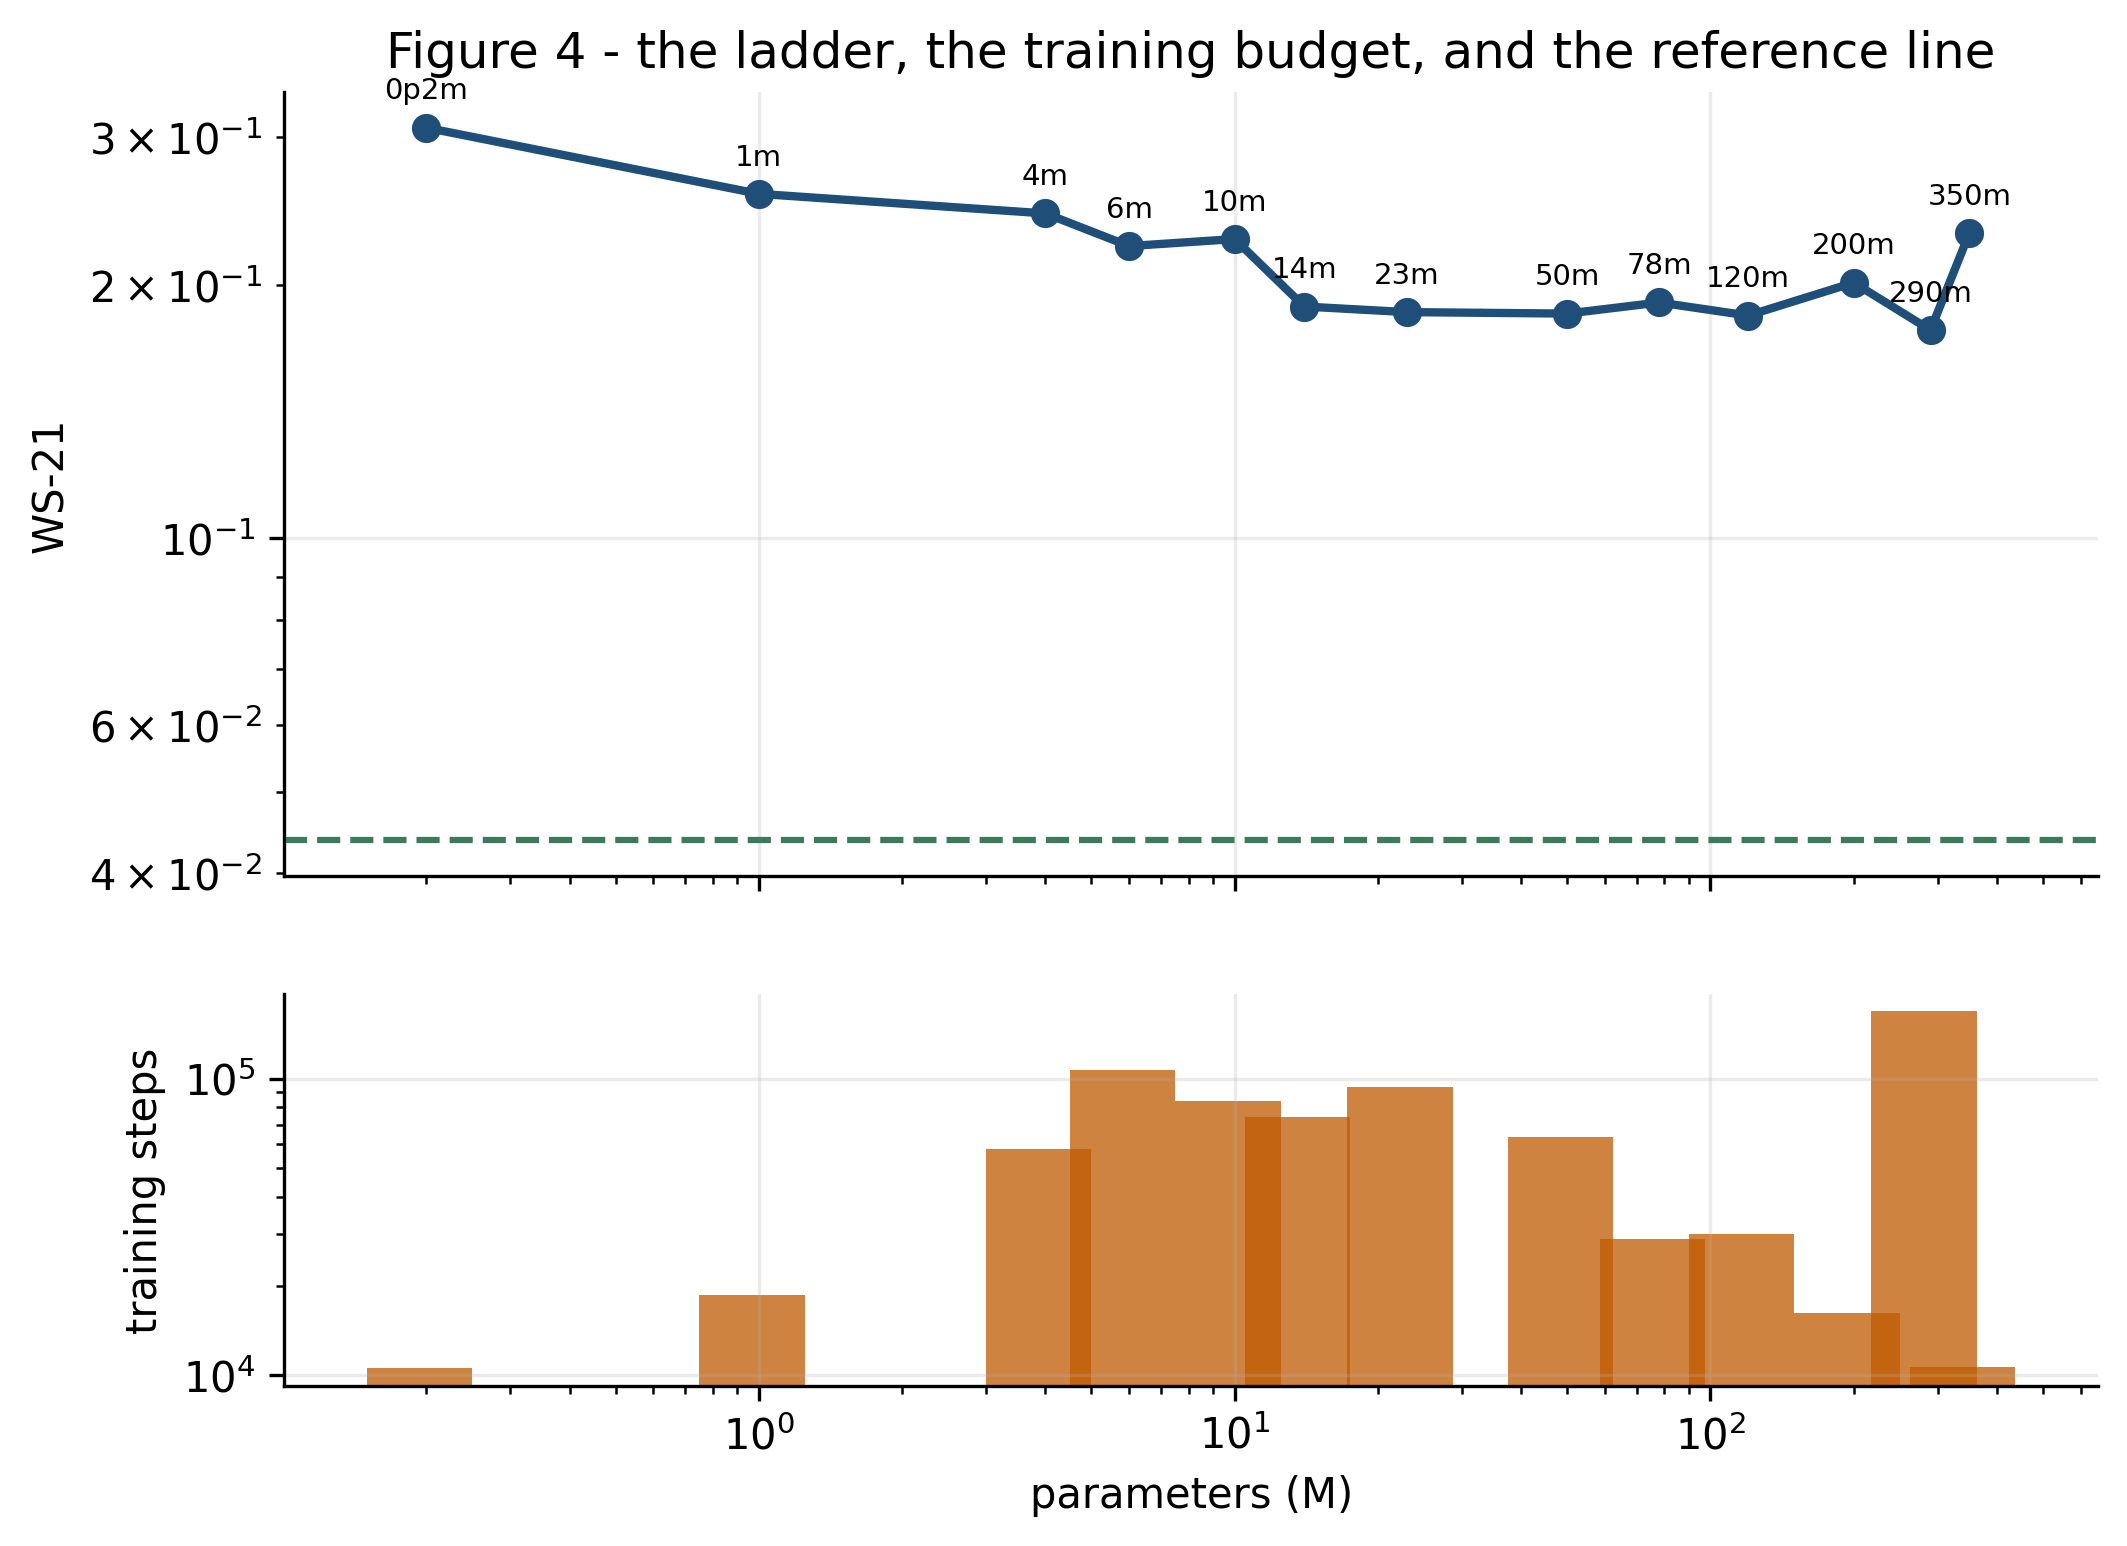

In [6]:
def params(m):
    import re
    g = re.search(r"-(\d+)p(\d+)m-", m) or re.search(r"-(\d+)m[-_]", m)
    if not g: return None
    return float(f"{g.group(1)}.{g.group(2)}") if g.lastindex == 2 else float(g.group(1))

lad = sorted((params(m), st.mean(ws(FIXED, m)), REG[m]["step"], m)
             for m in SCORED if m.startswith("m3-sp500-") and m.endswith("-s42")
             and params(m))
xs = [p for p, _, _, _ in lad]
fig, (ax, bx) = plt.subplots(2, 1, figsize=(7.8, 5.6), sharex=True,
                             gridspec_kw={"height_ratios": [2, 1]})
ax.plot(xs, [w for _, w, _, _ in lad], marker="o", lw=2, color=INK)
ax.axhline(HIST["ws21"], ls="--", lw=1.5, color=GOOD)
for p, w, _, m in lad:
    ax.annotate(m.replace("m3-sp500-", "").replace("-s42", ""), (p, w), fontsize=7,
                xytext=(0, 7), textcoords="offset points", ha="center")
ax.set_ylabel("WS-21"); ax.set_yscale("log")
ax.set_title("Figure 4 - the ladder, the training budget, and the reference line")
bx.bar(xs, [s for _, _, s, _ in lad], width=[p * .5 for p in xs], color=WARN, alpha=.75)
bx.set_xscale("log"); bx.set_yscale("log")
bx.set_xlabel("parameters (M)"); bx.set_ylabel("training steps")
show(fig)

*The ladder flattens near 14M and turns up exactly where the training budget collapses, so the tail is a budget artefact -- and every rung sits far above the old reference.*

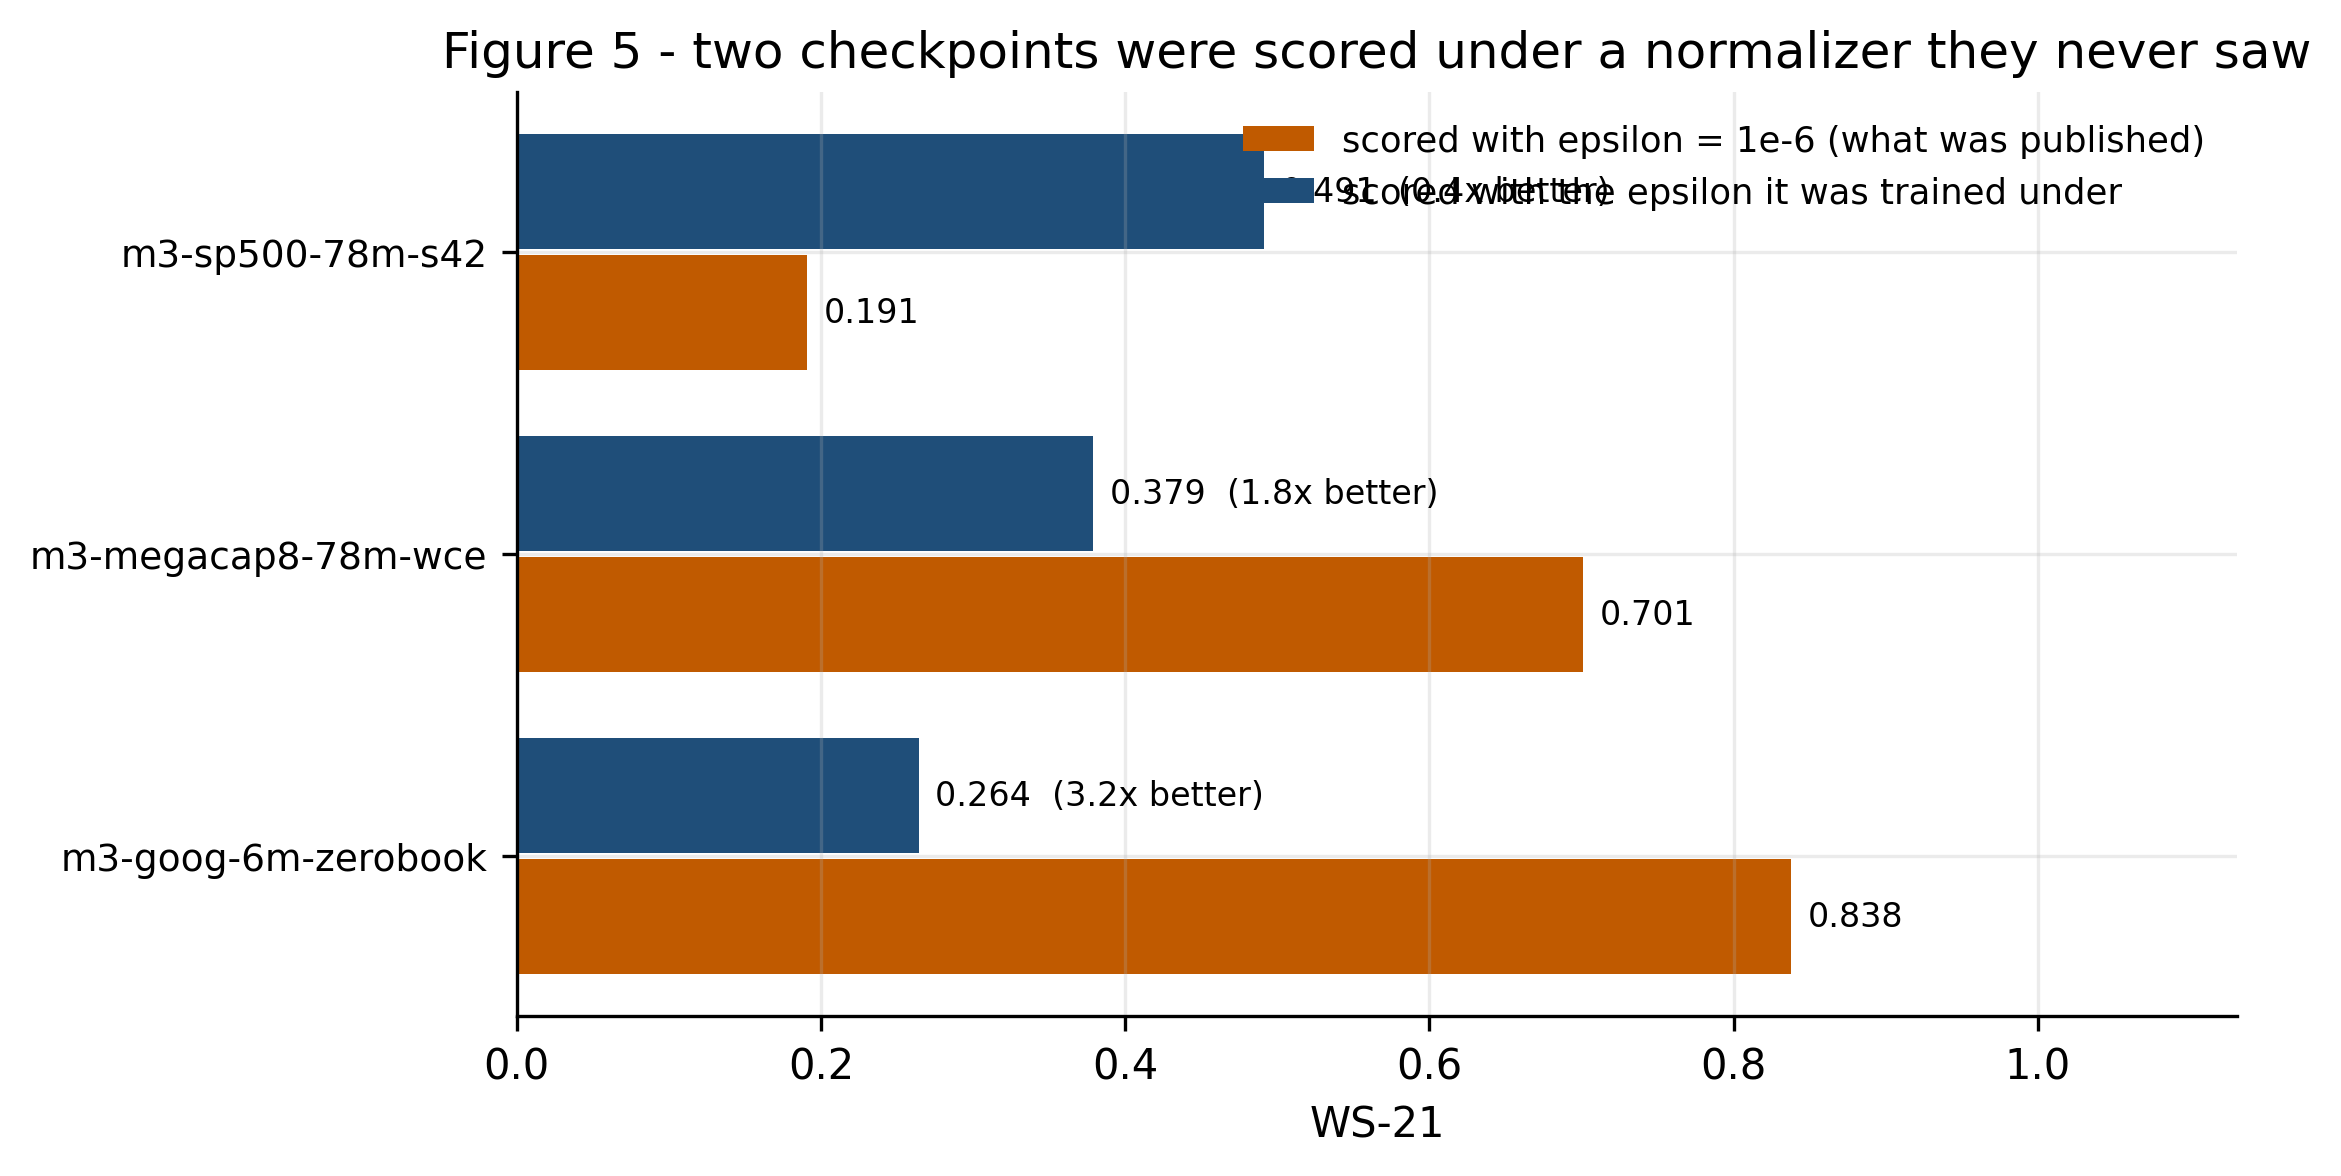

In [7]:
pairs = [(m, st.mean(ws(FIXED, m)), st.mean(ws(LEGACY, m))) for m in sorted(LEGACY)]
fig, ax = plt.subplots(figsize=(7.4, 4.0))
y = np.arange(len(pairs))
ax.barh(y - .2, [a for _, a, _ in pairs], height=.38, color=WARN,
        label="scored with epsilon = 1e-6 (what was published)")
ax.barh(y + .2, [b for _, _, b in pairs], height=.38, color=INK,
        label="scored with the epsilon it was trained under")
for i, (m, a, b) in enumerate(pairs):
    ax.annotate(f"{a:.3f}", (a, i - .2), fontsize=8, va="center",
                xytext=(4, 0), textcoords="offset points")
    ax.annotate(f"{b:.3f}  ({a/b:.1f}x better)", (b, i + .2), fontsize=8, va="center",
                xytext=(4, 0), textcoords="offset points")
ax.set_yticks(y); ax.set_yticklabels([m for m, _, _ in pairs], fontsize=9)
ax.set_xlabel("WS-21"); ax.set_xlim(0, max(a for _, a, _ in pairs) * 1.35)
ax.set_title("Figure 5 - two checkpoints were scored under a normalizer they never saw")
ax.legend(frameon=False, fontsize=8.5, loc="upper right"); show(fig)

*Restoring the training-time epsilon moves both flagged checkpoints by more than the entire spread of the leaderboard: they were mis-scored, not bad.*

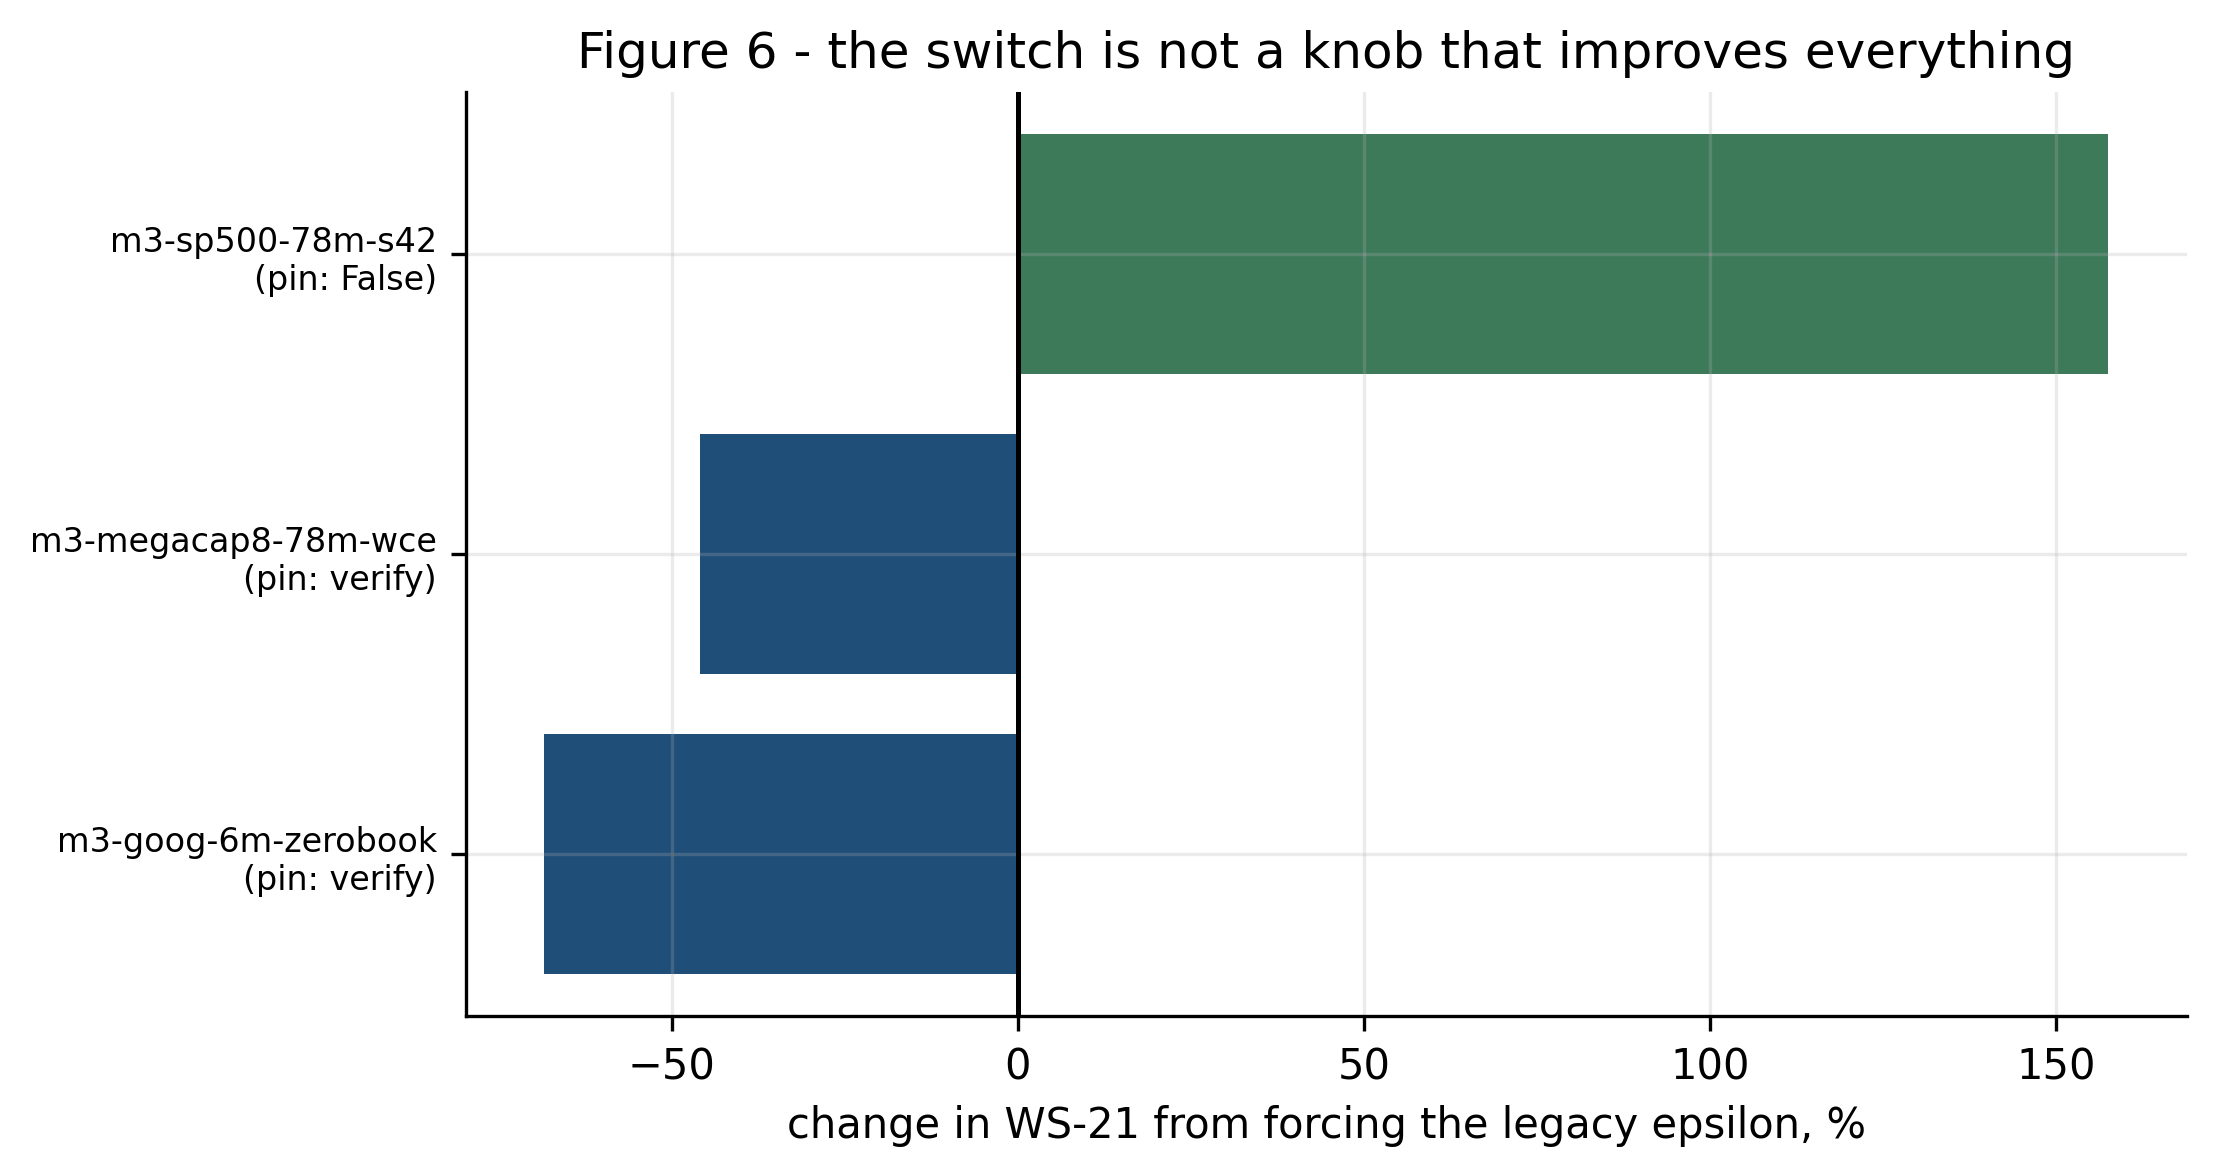

In [8]:
ctl = [m for m in LEGACY if PINS.get(m) is False]
fig, ax = plt.subplots(figsize=(7.4, 4.0))
names, deltas, cols = [], [], []
for m in sorted(LEGACY):
    a, b = st.mean(ws(FIXED, m)), st.mean(ws(LEGACY, m))
    names.append(m); deltas.append((b - a) / a * 100)
    cols.append(INK if PINS.get(m) == "verify" else GOOD)
ax.barh(np.arange(len(names)), deltas, color=cols)
ax.axvline(0, color="k", lw=1.2)
ax.set_yticks(np.arange(len(names)))
ax.set_yticklabels([f"{m}\n(pin: {PINS.get(m)})" for m in names], fontsize=8)
ax.set_xlabel("change in WS-21 from forcing the legacy epsilon, %")
ax.set_title("Figure 6 - the switch is not a knob that improves everything")
show(fig)

*Applied to a checkpoint whose pin says otherwise the same switch makes things worse, which is what makes this a correction rather than a knob.*

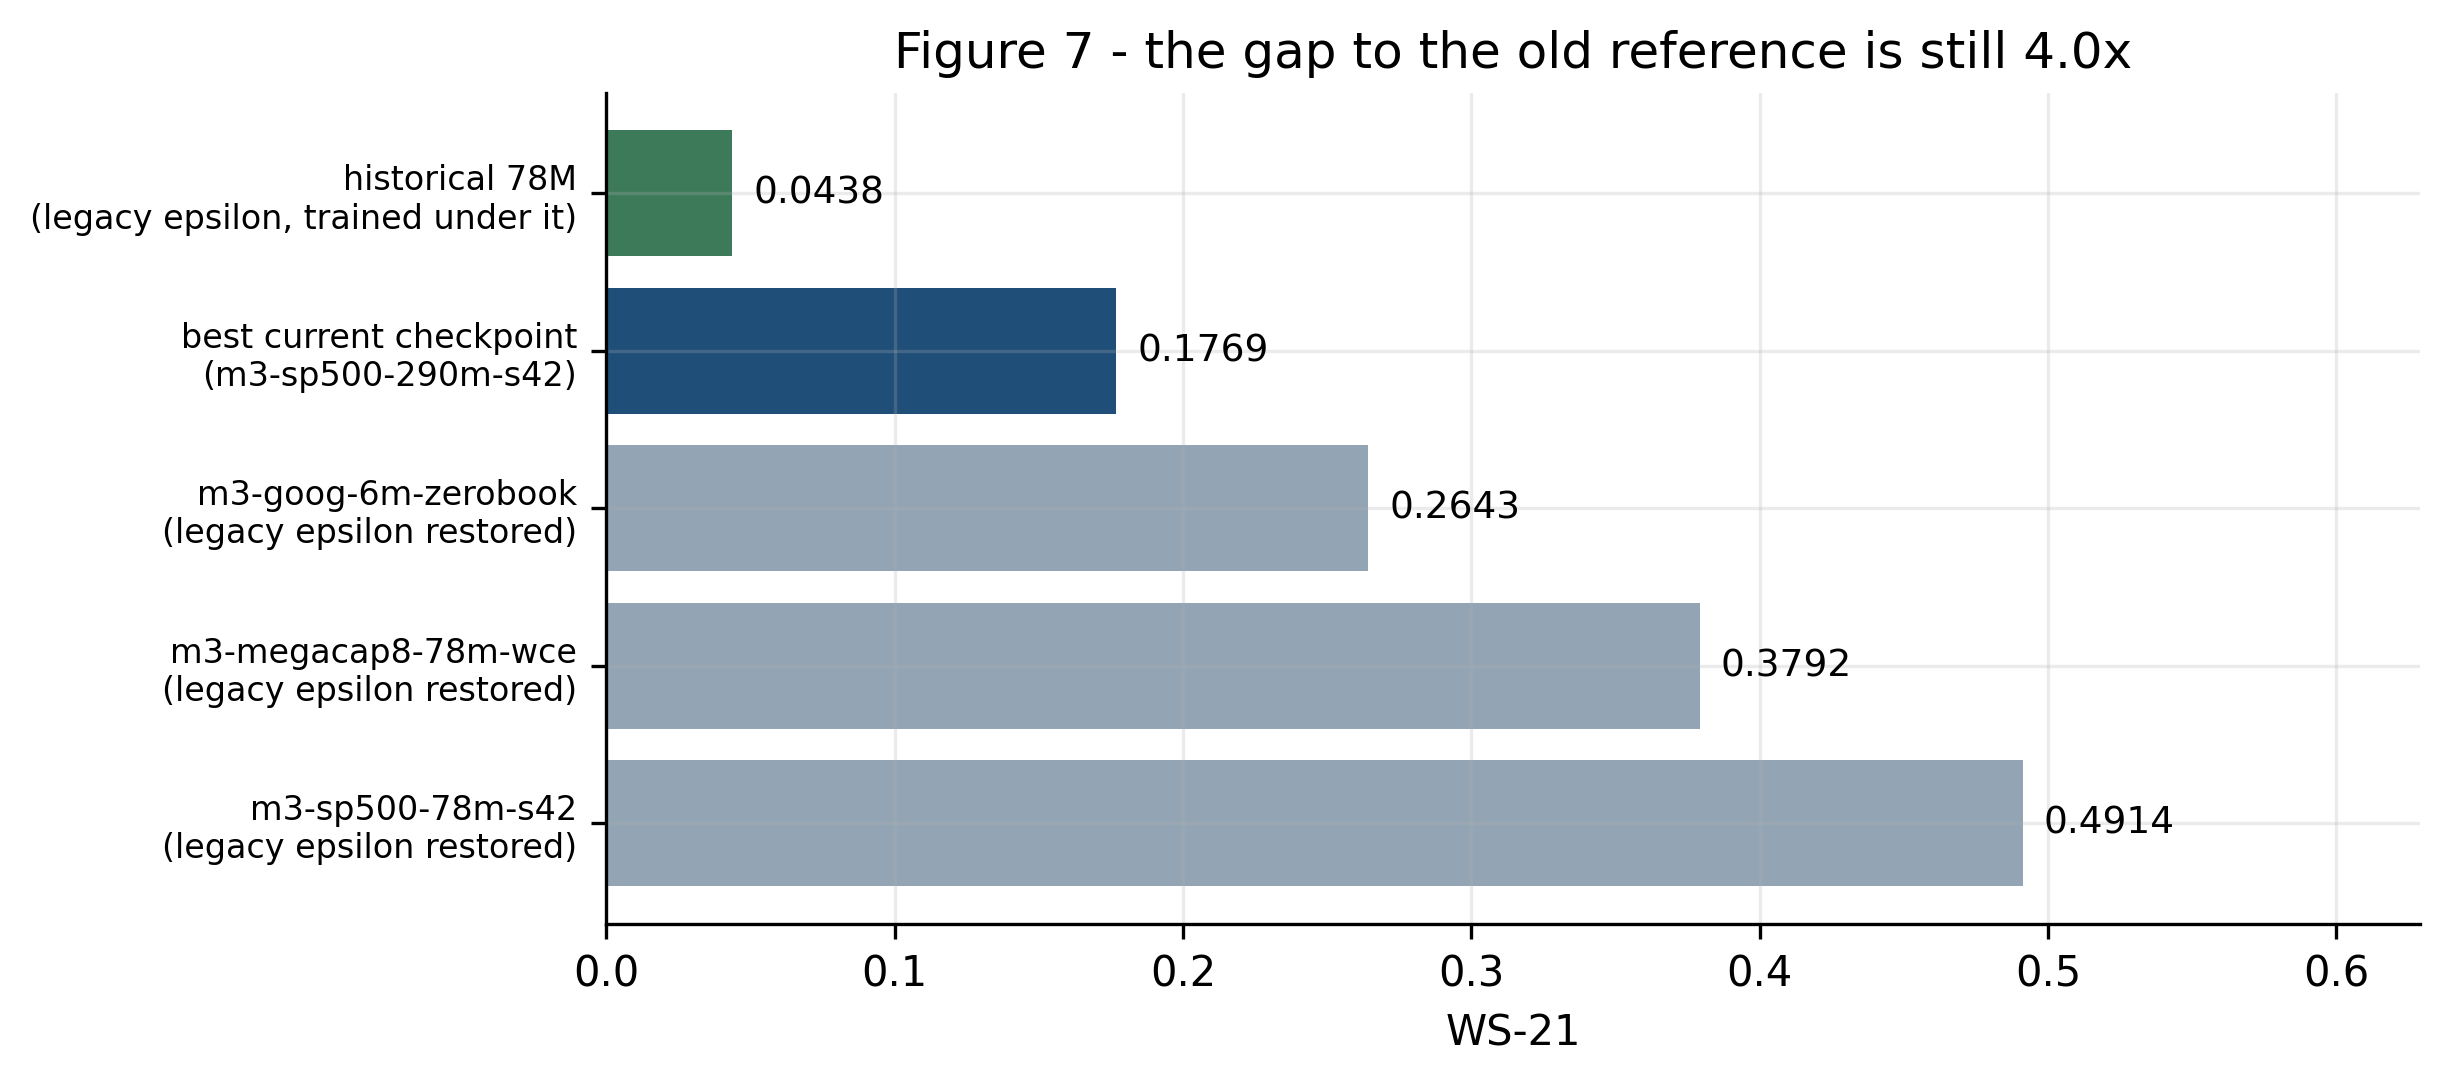

In [9]:
best = st.mean(ws(FIXED, SCORED[0]))
fig, ax = plt.subplots(figsize=(7.8, 3.6))
bars = [("historical 78M\n(legacy epsilon, trained under it)", HIST["ws21"], GOOD),
        (f"best current checkpoint\n({SCORED[0]})", best, INK)]
for m in sorted(LEGACY):
    bars.append((f"{m}\n(legacy epsilon restored)", st.mean(ws(LEGACY, m)), GREY))
ax.barh(np.arange(len(bars)), [v for _, v, _ in bars],
        color=[c for _, _, c in bars])
for i, (_, v, _) in enumerate(bars):
    ax.annotate(f"{v:.4f}", (v, i), fontsize=9, va="center",
                xytext=(5, 0), textcoords="offset points")
ax.set_yticks(np.arange(len(bars)))
ax.set_yticklabels([n for n, _, _ in bars], fontsize=8)
ax.invert_yaxis(); ax.set_xlim(0, max(v for _, v, _ in bars) * 1.28)
ax.set_xlabel("WS-21")
ax.set_title(f"Figure 7 - the gap to the old reference is still {best/HIST['ws21']:.1f}x")
show(fig)

*Even corrected, nothing in the zoo comes close to the pre-fix 78M reference -- the epsilon defect explains the two outliers, not the gap.*

### Table 1 - every scored checkpoint

In [10]:
rows = []
for m in SCORED:
    s = ws(FIXED, m); r = REG[m]
    rows.append({"model": m, "d_model": r["d_model"], "step": r["step"],
                 "WS-21": round(st.mean(s), 4),
                 "spread": round(max(s) - min(s), 4),
                 "KS-21": round(FIXED[m]["2026"]["ks21"], 4),
                 "last/first": round(FIXED[m]["2026"]["div_ratio"], 2),
                 "pin": str(PINS.get(m))})
pd.DataFrame(rows).set_index("model")

,d_model,step,WS-21,spread,KS-21,last/first,pin
model,,,,,,,
m3-sp500-290m-s42,2048,168200,0.1769,0.0045,0.1008,1.33,False
m3-goog-78m-u6gb,1024,28730,0.1816,0.0040,0.1038,1.24,False
m3-sp500-120m-s42,1280,29960,0.1841,0.0018,0.1059,1.35,False
m3-sp500-50m-s42,768,63410,0.1851,0.0024,0.1035,1.33,False
m3-sp500-23m-s42,512,93990,0.1858,0.0014,0.1088,1.42,False
m3-sp500-14m-s42,384,74490,0.1887,0.0095,0.1174,1.44,False
m3-sp500-78m-s42,1024,28730,0.1908,0.0048,0.1093,1.35,False
m3-78m-ftgoog-s42,1024,8514,0.1962,0.0087,0.1065,1.44,False
m3-sp500-200m-s42,1664,16220,0.2014,0.0108,0.1086,1.35,False


### Table 2 - the two re-scored checkpoints, against the old reference

In [11]:
rows = []
for m in sorted(LEGACY):
    a, b = ws(FIXED, m), ws(LEGACY, m)
    rows.append({"model": m, "pin": str(PINS.get(m)),
                 "eps=1e-6": round(st.mean(a), 4), "n": len(a),
                 "eps=trained": round(st.mean(b), 4), "n ": len(b),
                 "ratio": round(st.mean(a) / st.mean(b), 2)})
rows.append({"model": "historical 78M (reference)", "pin": "legacy",
             "eps=1e-6": None, "n": 0,
             "eps=trained": round(HIST["ws21"], 4), "n ": 1, "ratio": None})
pd.DataFrame(rows).set_index("model")

,pin,eps=1e-6,n,eps=trained,n,ratio
model,,,,,,
m3-goog-6m-zerobook,verify,0.8379,3,0.2643,3,3.17
m3-megacap8-78m-wce,verify,0.7012,3,0.3792,3,1.85
m3-sp500-78m-s42,False,0.1908,3,0.4914,2,0.39
historical 78M (reference),legacy,NaN,0,0.0438,1,NaN


## Conclusions

1. **Two published numbers were wrong, and the pin to prevent it already
   existed.** The harness scored every checkpoint with `epsilon=1e-6` while
   `model_store_pins.json` marked two of them as trained under the large
   epsilon. Correcting it moves them by 3.2x and 1.9x -- far more than the
   difference between any two rows of the leaderboard.
2. **The switch is a correction, not an improvement.** Forced onto a checkpoint
   the pin says was trained with the small epsilon, it makes the score worse.
   The rule is to match inference to training, in both directions.
3. **Most of the leaderboard is not ranked.** Below rank two the gaps fall
   inside the models' own generation-seed spreads.
4. **The 4x gap to the pre-fix 78M reference is untouched by any of this.**
   That reference was trained under the large epsilon; whether the semantics
   have to be present *from the start of training* to recover its quality is
   the question `artifacts/rmsnorm_train_ab/` was written to answer, and that
   train-time A/B has never run.